In [29]:
# Implement and compare Logistic Regression and Decision Trees on the Adult Income
# dataset for predicting income levels. Evaluate both models based on performance metrics
# and interpretability.
# Tasks:
# ● Load and preprocess the Adult Income dataset.
# ● Implement both Logistic Regression and Decision Trees.
# ● Compare the models based on metrics such as accuracy, precision, recall, and F1-
# score.
# ● Discuss the interpretability of both models and their suitability for the dataset.

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [31]:
data = fetch_openml("adult", version=2)

In [39]:
for col in data.columns:
    if data[col].dtype == 'object':
        data[col] = LabelEncoder().fit_transform(data[col])

In [49]:
x = pd.get_dummies(data.drop('class', axis=1))
temp = []
for val in data['class'].values:
    if val == '>50K':
        temp.append(1)
    else:
        temp.append(0)
y = pd.Series(temp)

In [50]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.fit_transform(x_test)

In [53]:
lr = LogisticRegression(max_iter = 1000)
lr.fit(x_train_s,y_train)
lr_pred = lr.predict(x_test_s)

In [52]:
dt = DecisionTreeClassifier(max_depth = 5)
dt.fit(x_train,y_train)
dt_pred = dt.predict(x_test)

In [54]:
results = []

models = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred
}

for name, pred in models.items():

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.856792,0.745455,0.612201,0.672289
1,Decision Tree,0.854847,0.784748,0.544369,0.642821


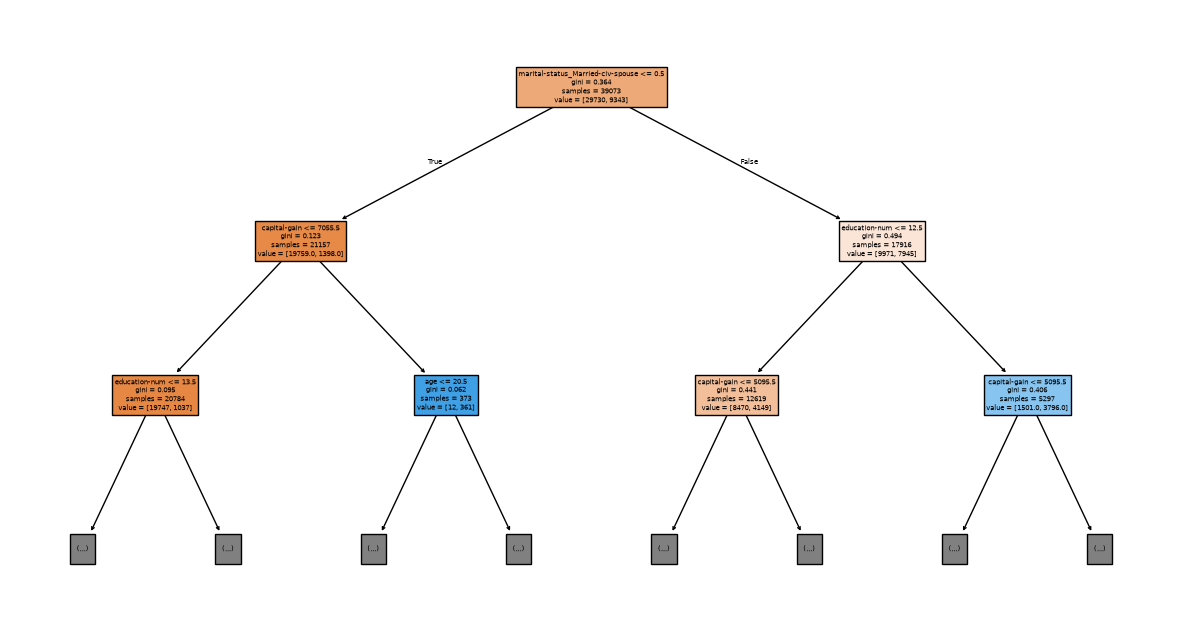

In [63]:
plt.figure(figsize = (15,8))
plot_tree(dt,feature_names = x.columns,filled = True,max_depth = 2)
plt.show()